# Cambodia STEPS — Feature Engineering & Preprocessing

**Input :** `newdata/steps_selected_before_ai_generation.csv` — 873 records, 36 STEPS columns  
**Output:** `newdata/cambodia_diabetes_final_clean.csv` — 873 records, 20 columns (19 features + target)

| STEPS column(s) | → | Output feature | Transformation |
|---|---|---|---|
| `h7a` | → | `Diabetes_binary` | 1→1, 2→0 |
| `sex` | → | `Sex` | 1(M)→1, 2(F)→0 |
| `age` | → | `Age` | kept as-is (25–64) |
| `c5` | → | `Education` | direct 1–7 scale |
| `m3`, `m4` | → | `BMI` | m4 / (m3/100)² |
| `m7` | → | `Waist_cm` | kept as-is |
| `h1`, `h2a`, BP readings | → | `HighBP` | doctor-diagnosed OR measured ≥140/90 |
| `b8` | → | `HighChol` | cholesterol measured (proxy) |
| `t1`, `t2` | → | `Smoker` | current or former smoker |
| `a3` | → | `AlcoholUse` | any alcohol in past 30 days |
| `a3`, `a5` | → | `HvyAlcoholConsump` | drank AND ≥4 binge episodes |
| `p1–p13` | → | `PhysActivity` | any PA module active |
| `p16a`, `p16b` | → | `SedentaryMinutes` | p16a×60 + p16b |
| `d1` | → | `Fruits` | d1>0 → 1 |
| `d3` | → | `Veggies` | d3>0 → 1 |

## 1. Imports

In [17]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_DIR     = '../newdata/'
INPUT_FILE   = DATA_DIR + 'steps_selected_before_ai_generation.csv'
OUTPUT_FILE  = DATA_DIR + 'cambodia_diabetes_final_clean.csv'

## 2. Load Raw STEPS Data

In [18]:
raw = pd.read_csv(INPUT_FILE)
print(f'Shape: {raw.shape}')
print(f'Columns: {raw.columns.tolist()}')
raw.head()

Shape: (873, 36)
Columns: ['sex', 'age', 'c4', 'c5', 'c8', 'c11', 't1', 't2', 'a3', 'a4', 'a5', 'a7', 'd1', 'd2', 'd3', 'd4', 'p1', 'p4', 'p7', 'p10', 'p13', 'p16a', 'p16b', 'h1', 'h2a', 'm3', 'm4', 'm7', 'm11a', 'm11b', 'm12a', 'm12b', 'm13a', 'm13b', 'b8', 'h7a']


,sex,age,c4,c5,c8,c11,t1,t2,a3,a4,...,m4,m7,m11a,m11b,m12a,m12b,m13a,m13b,b8,h7a
0,1,29,12,5,2,NaN,1,1.0,1.0,5.0,...,66.8,86.0,135.0,87.0,121.0,85.0,137.0,91.0,209.0,2
1,1,26,5,2,3,NaN,2,NaN,1.0,3.0,...,63.6,83.0,120.0,63.0,114.0,59.0,100.0,61.0,154.0,2
2,1,34,8,4,1,NaN,1,1.0,1.0,30.0,...,67.1,90.0,124.0,80.0,120.0,75.0,121.0,78.0,159.0,2
3,1,27,6,3,3,NaN,1,1.0,1.0,4.0,...,79.5,90.0,127.0,66.0,120.0,67.0,124.0,63.0,188.0,2
4,1,30,6,3,3,NaN,1,1.0,1.0,30.0,...,50.1,70.0,130.0,77.0,128.0,80.0,125.0,85.0,155.0,2


In [19]:
print('Missing values per column:')
miss = raw.isnull().sum()
print(miss[miss > 0].to_string())

Missing values per column:
c11     787
t2      738
a3      449
a4      556
a5      556
a7      556
d2      150
d4       10
h2a     122
m3       32
m4       32
m7       39
m11a     31
m11b     31
m12a     31
m12b     31
m13a     31
m13b     31
b8       41


## 3. Feature Engineering Manually

In [20]:
df = pd.DataFrame(index=raw.index)

# Target
df['Diabetes_binary'] = (raw['h7a'] == 1).astype(int)

# Demographics
df['Sex']       = (raw['sex'] == 1).astype(int) # 1=Male, 0=Female
df['Age']       = raw['age']
df['Education'] = raw['c5']

# Anthropometric
bmi_raw    = raw['m4'] / (raw['m3'] / 100) ** 2
df['BMI']      = bmi_raw.round(1).fillna(bmi_raw.round(1).median())
df['Waist_cm'] = raw['m7'].fillna(raw['m7'].median())

# Blood pressure
mean_systolic_bp = raw[['m11a', 'm12a', 'm13a']].mean(axis=1)
mean_systolic_bp = mean_systolic_bp.fillna(mean_systolic_bp.median())

mean_diastolic_bp = raw[['m11b', 'm12b', 'm13b']].mean(axis=1)
mean_diastolic_bp = mean_diastolic_bp.fillna(mean_diastolic_bp.median())

# HighBP: doctor-diagnosed OR measured hypertension
doctor_bp = (raw['h1'] == 1) & (raw['h2a'] == 1.0)
measured_bp = (mean_systolic_bp >= 140) | (mean_diastolic_bp >= 90)

df['HighBP'] = (doctor_bp | measured_bp).astype(int)

# Clinical
df['HighChol'] = (raw['b8'] >= 5.2).astype(int)  # cholesterol measured (proxy)

# Lifestyle
df['Smoker']           = ((raw['t1'] == 1) | (raw['t2'] == 1.0)).astype(int)
df['AlcoholUse']       = (raw['a3'] == 1.0).fillna(False).astype(int)
df['HvyAlcoholConsump'] = (
    (raw['a3'] == 1.0) & (raw['a5'] >= 4.0)
).fillna(False).astype(int)

all_inactive = (
    (raw['p1'] == 2) & (raw['p4'] == 2) & (raw['p7'] == 2) &
    (raw['p10'] == 2) & (raw['p13'] == 2)
)
df['PhysActivity']    = (~all_inactive).astype(int)
df['SedentaryMinutes'] = (raw['p16a'] * 60 + raw['p16b'].fillna(0)).astype(int)

# Dietary
df['Fruits']              = (raw['d1'] > 0).astype(int)
df['Veggies']             = (raw['d3'] > 0).astype(int)

print('Engineered features:')   
print(df.dtypes)
print(f'\nNulls remaining: {df.isnull().sum().sum()}')
print(f'Final shape: {df.shape}')

Engineered features:
Diabetes_binary        int64
Sex                    int64
Age                    int64
Education              int64
BMI                  float64
Waist_cm             float64
HighBP                 int64
HighChol               int64
Smoker                 int64
AlcoholUse             int64
HvyAlcoholConsump      int64
PhysActivity           int64
SedentaryMinutes       int64
Fruits                 int64
Veggies                int64
dtype: object

Nulls remaining: 0
Final shape: (873, 15)


## 4. Reorder Columns

In [21]:
FEATURE_ORDER = [
    'Diabetes_binary', 'Sex', 'Age', 'Education', 'BMI', 'Waist_cm',
    'HighBP', 'HighChol', 'Smoker', 'AlcoholUse', 'HvyAlcoholConsump',
    'PhysActivity', 'SedentaryMinutes', 'Fruits', 'Veggies',
]
df = df[FEATURE_ORDER]

assert df.isnull().sum().sum() == 0, 'Unexpected nulls after imputation'
assert set(df['Diabetes_binary'].unique()) == {0, 1}
print('All checks passed.')
print(f'Shape: {df.shape}  (14 features + 1 target)')
df.describe().round(2)

All checks passed.
Shape: (873, 15)  (14 features + 1 target)


,Diabetes_binary,Sex,Age,Education,BMI,Waist_cm,HighBP,HighChol,Smoker,AlcoholUse,HvyAlcoholConsump,PhysActivity,SedentaryMinutes,Fruits,Veggies
count,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00,873.00
mean,0.14,0.31,44.89,2.55,23.07,79.89,0.30,0.95,0.15,0.36,0.11,0.93,257.38,0.84,0.99
std,0.35,0.46,11.10,1.24,3.95,10.60,0.46,0.21,0.36,0.48,0.32,0.26,131.83,0.37,0.11
min,0.00,0.00,25.00,1.00,12.90,53.00,0.00,0.00,0.00,0.00,0.00,0.00,20.00,0.00,0.00
25%,0.00,0.00,36.00,2.00,20.30,73.00,0.00,1.00,0.00,0.00,0.00,1.00,180.00,1.00,1.00
50%,0.00,0.00,46.00,2.00,22.60,79.00,0.00,1.00,0.00,0.00,0.00,1.00,240.00,1.00,1.00
75%,0.00,1.00,53.00,3.00,25.40,87.00,1.00,1.00,0.00,1.00,0.00,1.00,360.00,1.00,1.00
max,1.00,1.00,64.00,7.00,38.50,122.00,1.00,1.00,1.00,1.00,1.00,1.00,750.00,1.00,1.00


## 5. Class Distribution

Diabetes_binary
No Diabetes    751
Diabetes       122
Name: count, dtype: int64
Positive class rate: 14.0%


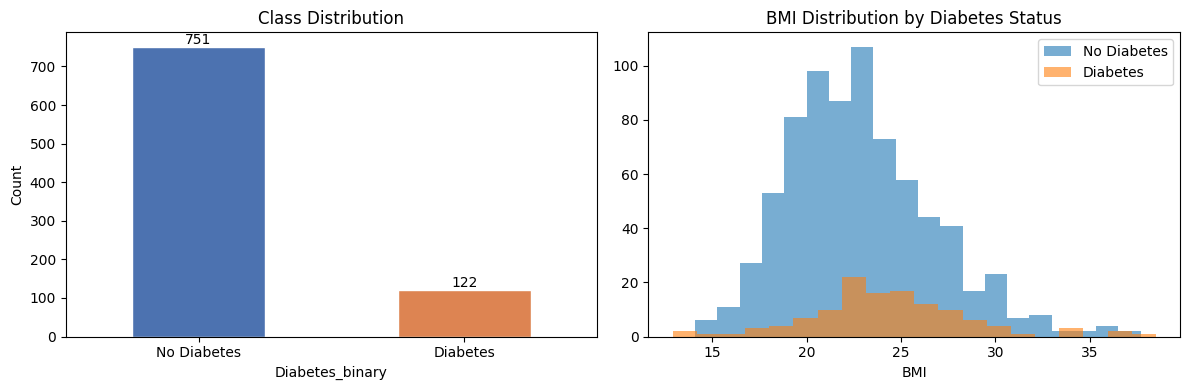

In [22]:
counts = df['Diabetes_binary'].value_counts().rename({0: 'No Diabetes', 1: 'Diabetes'})
print(counts)
print(f'Positive class rate: {df["Diabetes_binary"].mean()*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'], edgecolor='white')
axes[0].set_title('Class Distribution')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['No Diabetes', 'Diabetes'], rotation=0)
for p in axes[0].patches:
    axes[0].annotate(str(int(p.get_height())),
                     (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')

for label, grp in df.groupby('Diabetes_binary'):
    axes[1].hist(grp['BMI'], bins=20, alpha=0.6, label=['No Diabetes','Diabetes'][label])
axes[1].set_title('BMI Distribution by Diabetes Status')
axes[1].set_xlabel('BMI')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Feature Summary Heatmap

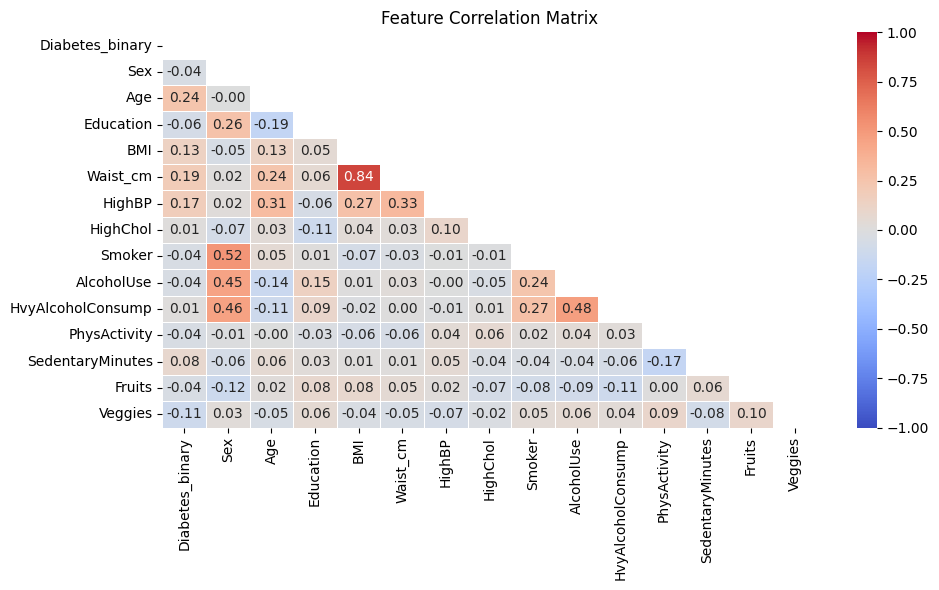

In [23]:
plt.figure(figsize=(10, 6))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## 7. Save Cleaned Dataset

In [25]:
df.to_csv(OUTPUT_FILE, index=False)
print(f'Saved {len(df)} rows x {df.shape[1]} cols → {OUTPUT_FILE}')
print(df.head())

Saved 873 rows x 15 cols → ../newdata/cambodia_diabetes_final_clean.csv
   Diabetes_binary  Sex  Age  Education   BMI  Waist_cm  HighBP  HighChol  \
0                0    1   29          5  25.5      86.0       0         1   
1                0    1   26          2  23.4      83.0       0         1   
2                0    1   34          4  24.4      90.0       0         1   
3                0    1   27          3  28.2      90.0       0         1   
4                0    1   30          3  20.7      70.0       0         1   

   Smoker  AlcoholUse  HvyAlcoholConsump  PhysActivity  SedentaryMinutes  \
0       1           1                  0             1               240   
1       0           1                  0             1               180   
2       1           1                  0             1               150   
3       1           1                  1             1               300   
4       1           1                  1             1               180   

   Fruit